# Step 4: Testing & Prediction on unseen animals
The 12 images in `predict/` are separate drawings that were **never** used for training or augmentation.

In [2]:
# Setup: installs any missing library the first time (safe to re-run)
import importlib, importlib.util, subprocess, sys
needed = {'tensorflow': 'tensorflow', 'cv2': 'opencv-python', 'sklearn': 'scikit-learn',
          'matplotlib': 'matplotlib', 'PIL': 'pillow'}
missing = [pkg for mod, pkg in needed.items() if importlib.util.find_spec(mod) is None]
if missing:
    print('Installing:', missing)
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
    importlib.invalidate_caches()
print('All libraries ready.')

All libraries ready.


Predicted Class: Bloopsy
Probability: 1.0000


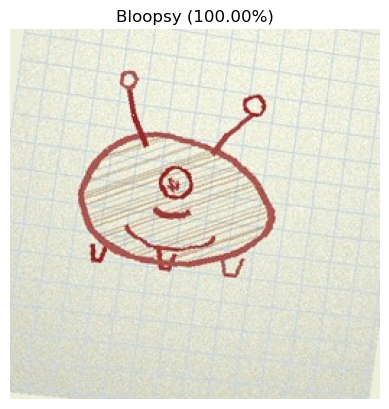

In [6]:
import os

import cv2
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

path = 'predict'
model_save_path = 'model_trained_data.h5'
class_labels = {0: 'Bloopsy', 1: 'Zigrill'}

model = tf.keras.models.load_model(model_save_path, compile=False)

def test_image(img_name, show=True):
    img_path = os.path.join(path, img_name)
    original_img = cv2.imread(img_path)            # BGR, same as training
    if original_img is None:
        print(f'Image not found: {img_path}')
        return None
    resized_img = cv2.resize(original_img, (128, 128)) / 255.0
    input_data = resized_img.reshape(1, 128, 128, 3)

    raw_probability = model.predict(input_data, verbose=0)[0][0]
    if raw_probability > 0.5:
        class_index, probability = 1, raw_probability
    else:
        class_index, probability = 0, 1.0 - raw_probability

    if show:
        print(f'Predicted Class: {class_labels[class_index]}')
        print(f'Probability: {probability:.4f}')
        plt.imshow(cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB))
        plt.title(f'{class_labels[class_index]} ({probability:.2%})')
        plt.axis('off'); plt.show()
    return class_index, probability

_ = test_image('0-0.jpg')

Predicted Class: Zigrill
Probability: 1.0000


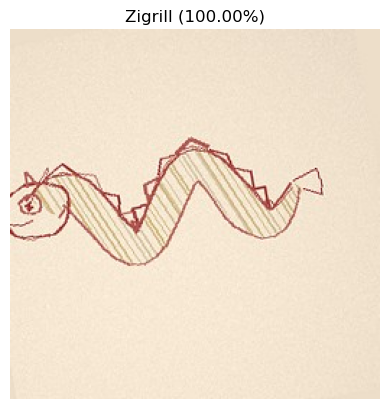

In [4]:
_ = test_image('1-0.jpg')

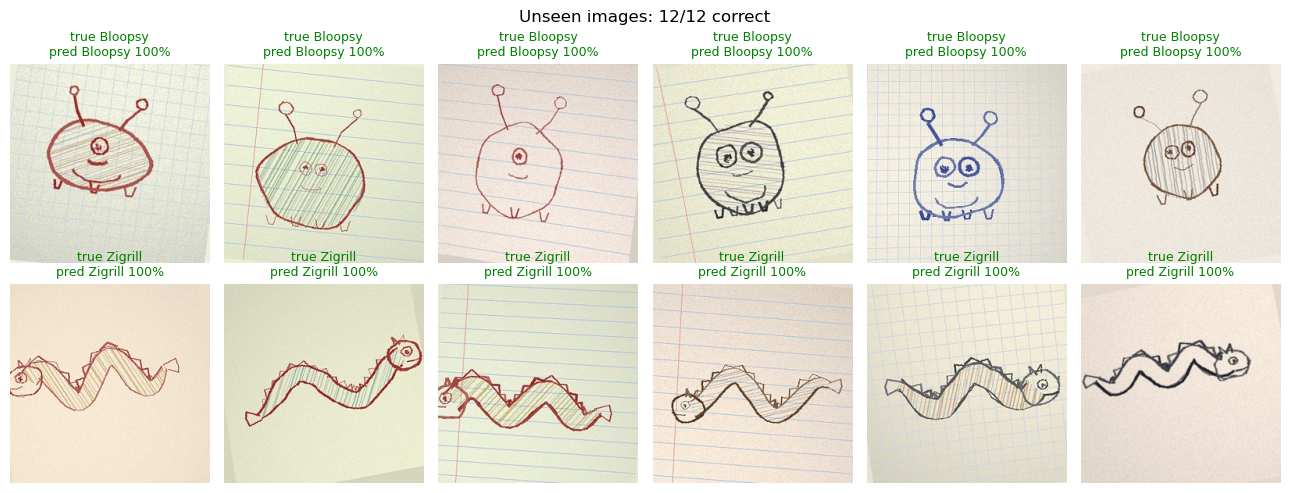

Unseen accuracy: 12/12 = 100%


In [5]:
# Predict all 12 unseen images; the true label is the first character of the file name
files = sorted(f for f in os.listdir(path) if f.lower().endswith(('.jpg', '.png')))
fig, axes = plt.subplots(2, 6, figsize=(13, 5))
correct = 0
for ax, f in zip(axes.ravel(), files):
    true = int(f[0])
    pred_idx, prob = test_image(f, show=False)
    correct += int(pred_idx == true)
    img = cv2.cvtColor(cv2.imread(os.path.join(path, f)), cv2.COLOR_BGR2RGB)
    ax.imshow(img); ax.axis('off')
    ax.set_title(f'true {class_labels[true]}\npred {class_labels[pred_idx]} {prob:.0%}', fontsize=9,
                 color='green' if pred_idx == true else 'red')
plt.suptitle(f'Unseen images: {correct}/{len(files)} correct')
plt.tight_layout(); plt.savefig('results/predictions_unseen.png', dpi=100); plt.show()
print(f'Unseen accuracy: {correct}/{len(files)} = {correct/len(files):.0%}')